<h1 style="font-size: 42px;">Abnormal Flight Investigation</h1>

In [2]:
# Purpose: Document and justify the exclusion of flight
#          f53dabf1-a0fb-433e-8ba8-f09c569db684
#          from all subsequent analysis
#
# Evidence: Sensor logging fault confirmed by:
#   1. Cell count recorded as 0 throughout entire flight
#   2. Computed voltage per cell = 10.27 V (impossible for LiPo)
#   3. 100% of rows flagged as voltage_per_cell_suspicious
#
# This notebook does NOT modify any existing data files.
# The exclusion is implemented in 02b_v2 preprocessing.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR      = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project")
SPLIT_DIR     = BASE_DIR / "splits"
INVEST_DIR    = BASE_DIR / "investigation_outputs"
OUTPUT_DIR    = BASE_DIR / "investigation_outputs" / "flight_removal"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FAULT_FLIGHT_ID = "f53dabf1-a0fb-433e-8ba8-f09c569db684"

## 1. Load original splits and extract the faulty flight

In [8]:

# ============================================================
# CORRECT LOADING — use original pre-removal CSV splits
# These still contain f53dabf1 because removal happened
# AFTER these files were created in notebook 02b
# ============================================================

ORIGINAL_SPLITS = BASE_DIR / "splits"

dfs = []
for fname in [
    "train_model_ready_selected_features.csv",
    "val_model_ready_selected_features.csv",
    "test_model_ready_selected_features.csv"
]:
    path = ORIGINAL_SPLITS / fname
    if path.exists():
        dfs.append(pd.read_csv(path))
        print(f"Loaded: {fname}")

full_df = pd.concat(dfs, ignore_index=True)

# Compute voltage_per_cell manually since not in these CSVs
full_df["voltage_per_cell"] = (
    full_df["battery_status__voltage_v"] /
    full_df["battery_status__cell_count"].replace(0, np.nan)
)

# Compute suspicious flag
full_df["voltage_per_cell_suspicious"] = (
    (full_df["voltage_per_cell"] < 3.0) |
    (full_df["voltage_per_cell"] > 4.5)
).astype(int)

print(f"\nShape: {full_df.shape}")
print(f"Flights: {full_df['log_id'].nunique()}")

# Verify faulty flight exists
fault_df = full_df[full_df["log_id"] == FAULT_FLIGHT_ID].copy()
print(f"Faulty flight rows: {len(fault_df)}")
print(f"voltage_per_cell in fault_df: {fault_df['voltage_per_cell'].unique()[:3]}")

Loaded: train_model_ready_selected_features.csv
Loaded: val_model_ready_selected_features.csv
Loaded: test_model_ready_selected_features.csv

Shape: (971822, 21)
Flights: 168
Faulty flight rows: 4897
voltage_per_cell in fault_df: [nan]


## 2. Extract the faulty flight

In [15]:
fault_df = full_df[full_df["log_id"] == FAULT_FLIGHT_ID].copy()

print("=" * 60)
print("FAULTY FLIGHT PROFILE")
print("=" * 60)
print(f"\nFlight ID  : {FAULT_FLIGHT_ID}")
print(f"Label      : {fault_df['dataset_label'].iloc[0]}")
print(f"Total rows : {len(fault_df)}")
print(f"Duration   : {fault_df['time_s'].max() - fault_df['time_s'].min():.1f} seconds")

# Key evidence columns
evidence_cols = [
    "battery_status__cell_count",
    "battery_status__voltage_v",
    "battery_status__voltage_filtered_v",
    "power_w",
    "battery_status__remaining",
]

if "voltage_per_cell" in fault_df.columns:
    evidence_cols.append("voltage_per_cell")
if "voltage_per_cell_suspicious" in fault_df.columns:
    evidence_cols.append("voltage_per_cell_suspicious")

available = [c for c in evidence_cols if c in fault_df.columns]

print("\nFaulty flight statistics:")
print(fault_df[available].describe().round(4).to_string())

FAULTY FLIGHT PROFILE

Flight ID  : f53dabf1-a0fb-433e-8ba8-f09c569db684
Label      : abnormal
Total rows : 4897
Duration   : 489.6 seconds

Faulty flight statistics:
       battery_status__cell_count  battery_status__voltage_v  battery_status__voltage_filtered_v    power_w  battery_status__remaining  voltage_per_cell  voltage_per_cell_suspicious
count                      4897.0                  4897.0000                           4897.0000  4897.0000                     4897.0               0.0                       4897.0
mean                          0.0                    10.2649                             10.2710   157.7880                        1.0               NaN                          0.0
std                           0.0                     0.3565                              0.3374    22.2536                        0.0               NaN                          0.0
min                           0.0                     9.3480                              9.5750     0.00

## 3. Compare against normal fleet statistics

In [16]:
normal_df = full_df[full_df["dataset_label"] == "normal"]

print("=" * 70)
print("COMPARISON: Faulty Flight vs Normal Fleet")
print("=" * 70)
print(f"\n{'Metric':<45} {'Faulty flight':>15} {'Normal fleet mean':>18}")
print("-" * 80)

compare_cols = [
    ("battery_status__cell_count",        "Cell count"),
    ("battery_status__voltage_filtered_v","Filtered voltage (V)"),
    ("power_w",                           "Power draw (W)"),
    ("battery_status__remaining",         "Battery remaining (0-1)"),
]

if "voltage_per_cell" in fault_df.columns:
    compare_cols.append(("voltage_per_cell", "Voltage per cell (V)"))

for col, label in compare_cols:
    if col in fault_df.columns and col in normal_df.columns:
        fault_mean  = fault_df[col].mean()
        normal_mean = normal_df[col].mean()
        print(f"{label:<45} {fault_mean:>15.4f} {normal_mean:>18.4f}")

if "voltage_per_cell_suspicious" in fault_df.columns:
    susp_pct = fault_df["voltage_per_cell_suspicious"].mean() * 100
    print(f"\n{'Suspicious voltage rows (%)':.<45} {susp_pct:>15.1f}%")
    print(f"{'Normal fleet suspicious rows (%)':.<45} "
          f"{normal_df['voltage_per_cell_suspicious'].mean()*100:>15.1f}%"
          if "voltage_per_cell_suspicious" in normal_df.columns else "")

COMPARISON: Faulty Flight vs Normal Fleet

Metric                                          Faulty flight  Normal fleet mean
--------------------------------------------------------------------------------
Cell count                                             0.0000             3.2545
Filtered voltage (V)                                  10.2710            12.6878
Power draw (W)                                       157.7880            99.6338
Battery remaining (0-1)                                1.0000             0.7045
Voltage per cell (V)                                      nan             3.9027

Suspicious voltage rows (%)..................             0.0%
Normal fleet suspicious rows (%).............            12.6%


## 4. Time series plot showing the fault

In [21]:
# Replace the y_max line with this
vpc_clean = vpc_vals[np.isfinite(vpc_vals)]

if len(vpc_clean) == 0:
    print("WARNING: all voltage_per_cell values are NaN/Inf")
    print("Recomputing from raw voltage / cell_count...")
    raw_v   = fault_sorted["battery_status__voltage_v"].values
    raw_c   = fault_sorted["battery_status__cell_count"].values
    print(f"  cell_count unique values: {np.unique(raw_c)}")
    print(f"  voltage range: {raw_v.min():.2f} – {raw_v.max():.2f} V")
    # Show pack voltage directly since per-cell is undefined
    vpc_clean = raw_v
    vpc_mean  = float(raw_v.mean())
    ax.plot(time, raw_v, color="#E53935", linewidth=2,
            label=f"Pack voltage ({vpc_mean:.2f} V total)")
    ax.set_title("Pack Voltage shown — per-cell undefined (cell_count=0)")
else:
    vpc_mean = float(vpc_clean.mean())
    ax.plot(time, vpc_vals, color="#E53935", linewidth=2,
            label=f"Faulty flight ({vpc_mean:.2f} V/cell)")
    ax.axhline(4.2, color="orange", linestyle="--",
               linewidth=1.5, label="Max LiPo (4.2 V)")
    ax.axhline(3.0, color="green",  linestyle="--",
               linewidth=1.5, label="Min LiPo (3.0 V)")

y_max = float(np.nanmax(vpc_clean)) * 1.15
y_max = y_max if np.isfinite(y_max) else 15.0
ax.set_ylim(0, y_max)

Recomputing from raw voltage / cell_count...
  cell_count unique values: [0.]
  voltage range: 9.35 – 12.30 V


(0.0, 14.145)

cell_count unique values : [0.]
pack voltage range       : 9.35 – 12.30 V
fleet median cell count  : 3


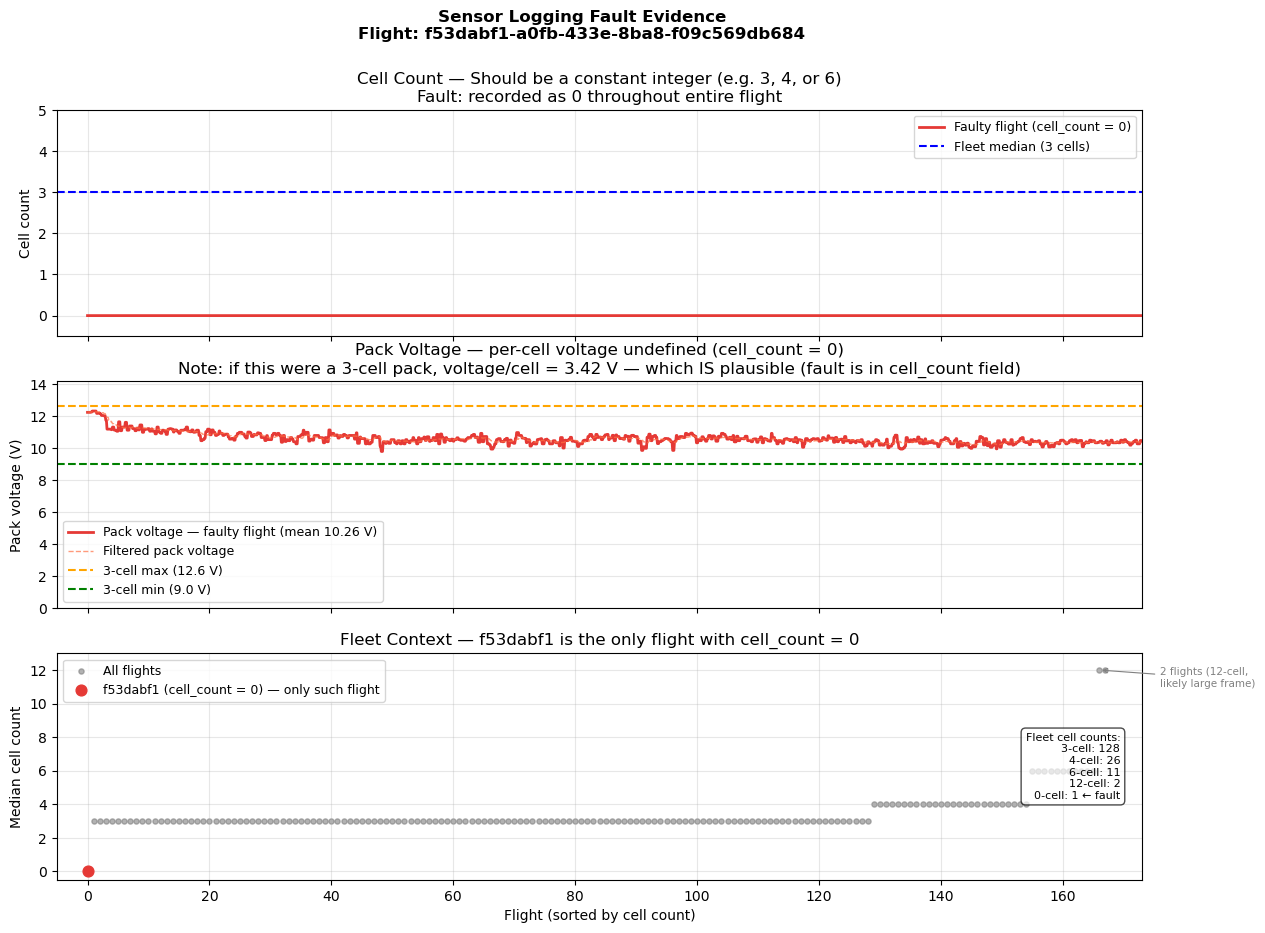

In [30]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
fig.suptitle(
    f"Sensor Logging Fault Evidence\nFlight: {FAULT_FLIGHT_ID}",
    fontsize=12, fontweight="bold"
)

fault_sorted = fault_df.sort_values("time_s").reset_index(drop=True)
time = fault_sorted["time_s"]

# Raw values we will use throughout
raw_cell_count = fault_sorted["battery_status__cell_count"].values
raw_voltage    = fault_sorted["battery_status__voltage_v"].values
raw_voltage_f  = fault_sorted["battery_status__voltage_filtered_v"].values

fleet_median_cells = float(
    full_df[full_df["dataset_label"] == "normal"]
    ["battery_status__cell_count"].median()
)

print(f"cell_count unique values : {np.unique(raw_cell_count)}")
print(f"pack voltage range       : {raw_voltage.min():.2f} – "
      f"{raw_voltage.max():.2f} V")
print(f"fleet median cell count  : {fleet_median_cells:.0f}")

# ── Panel 1: Cell count ───────────────────────────────────────
ax = axes[0]
ax.plot(time, raw_cell_count,
        color="#E53935", linewidth=2,
        label=f"Faulty flight (cell_count = {int(raw_cell_count.mean())})")
ax.axhline(fleet_median_cells,
           color="blue", linestyle="--", linewidth=1.5,
           label=f"Fleet median ({fleet_median_cells:.0f} cells)")
ax.set_ylabel("Cell count", fontsize=10)
ax.set_title(
    "Cell Count — Should be a constant integer (e.g. 3, 4, or 6)\n"
    "Fault: recorded as 0 throughout entire flight"
)
ax.set_ylim(-0.5, fleet_median_cells + 2)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# ── Panel 2: Pack voltage (not per-cell — denominator is 0) ──
ax = axes[1]
pack_mean = float(raw_voltage.mean())
ax.plot(time, raw_voltage,
        color="#E53935", linewidth=2,
        label=f"Pack voltage — faulty flight (mean {pack_mean:.2f} V)")
ax.plot(time, raw_voltage_f,
        color="#FF7043", linewidth=1, linestyle="--",
        label="Filtered pack voltage", alpha=0.7)

# Reference lines for what a healthy 3-cell pack looks like
ax.axhline(3 * 4.2, color="orange", linestyle="--",
           linewidth=1.5, label="3-cell max (12.6 V)")
ax.axhline(3 * 3.0, color="green",  linestyle="--",
           linewidth=1.5, label="3-cell min (9.0 V)")

v_max = float(np.nanmax(raw_voltage))
ax.set_ylim(0, v_max * 1.15)
ax.set_ylabel("Pack voltage (V)", fontsize=10)
ax.set_title(
    "Pack Voltage — per-cell voltage undefined (cell_count = 0)\n"
    f"Note: if this were a 3-cell pack, voltage/cell = "
    f"{pack_mean/3:.2f} V — which IS plausible (fault is in cell_count field)"
)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# ── Panel 3: Fleet context — cell_count per flight ───────────
ax = axes[2]
per_flight = (full_df.groupby("log_id")["battery_status__cell_count"]
              .median().sort_values().reset_index(drop=True))

ax.scatter(range(len(per_flight)), per_flight,
           s=14, color="grey", alpha=0.6, label="All flights")
fault_val = 0
fault_idx = per_flight[per_flight == fault_val].index
ax.scatter(fault_idx, [fault_val]*len(fault_idx),
           s=60, color="#E53935", zorder=3,
           label=f"f53dabf1 (cell_count = 0) — only such flight")

ax.set_ylabel("Median cell count", fontsize=10)
ax.set_xlim(-5, len(per_flight) + 5)
ax.set_xlabel("Flight (sorted by cell count)", fontsize=10)
ax.set_title("Fleet Context — f53dabf1 is the only flight with cell_count = 0")
ax.set_ylim(-0.5, per_flight.max() + 1)
ax.annotate("2 flights (12-cell,\nlikely large frame)", 
            xy=(per_flight[per_flight == 12].index[0], 12),
            xytext=(per_flight[per_flight == 12].index[0] + 10, 11),
            fontsize=7.5, color="grey",
            arrowprops=dict(arrowstyle="->", color="grey", lw=0.8))
ax.legend(fontsize=9)
ax.text(0.98, 0.5,
        "Fleet cell counts:\n3-cell: 128\n4-cell: 26\n6-cell: 11\n12-cell: 2\n0-cell: 1 ← fault",
        transform=ax.transAxes, fontsize=8, va="center", ha="right",
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.7))
ax.grid(True, alpha=0.3)